# PathSnap data analysis and preprocessing decisions

**Purpose:** validate the complete supplied PathSnap dataset and establish the training-derived preprocessing decisions required before model training. This notebook does not train a model.

**Partitions:** `train` (80 trips) supplies every learned threshold, transform and decision. `student_test` (10 trips) receives the fixed flagging logic and is used only for descriptive shift checks. The supplied workspace has no evaluator partition.

Run from the repository root with **Restart and Run All**.

## 6.1 Setup and CONFIG
All thresholds are defined once in `CONFIG`; no magic numbers are used elsewhere.

## 6.2 Inventory
Discover partitions and report file presence, sizes, and row counts.

## 6.3 Schema and validity
Parse headerless files using explicit dtypes; validate coordinates and ID bounds.

## 6.4 Index spaces
GPS rows, node IDs, arc IDs, and route positions are separate spaces. Rows are never aligned across files. GPS-to-road links use only projected geometry.

## 6.5-6.8 Quality analysis
Count duplicates, inspect time gaps and projected speeds, then form explicit keep/flag/drop decisions. Training-only drops are markers; student-test rows are never removed.

## 6.9-6.12 Network, route, candidates, and labels
Inspect directed topology, route continuity, GPS-to-arc candidates, and nearest vs monotonic route labels on a fixed training pilot. Networks are compared across trips to determine whether arc IDs are local.

## 6.13 Feature analysis
Inspect candidate features, distributions, correlations, and simple training-only discrimination on the pilot.

## 6.14 Partition shift
Run descriptive train-vs-student KS checks without changing any decision.

## 6.15 Maps and next step
Save a Folium training map. Section 6.16 (writing cleaned data and frozen configuration) must wait for confirmation of candidate settings and the label rule.


n_track                     n_nodes                       n_arcs  \
               count  min  median    max   count   min  median     max  count   
partition                                                                       
student_test      10  262  1420.0   3958      10  1770  6596.5   26635     10   
train             80  361  1529.0  19313      80   299  9608.0  155003     80   

                                    n_route                   
               min   median     max   count min median   max  
partition                                                     
student_test  3577  13145.0   56027      10  95  250.0  1323  
train          649  19526.5  307392      80  59  280.0  2266

,track_nan,nodes_nan,invalid_coord,zero_zero,bad_arc_endpoint,bad_route_arc
partition,,,,,,
student_test,0,0,0,0,0,0
train,0,0,0,0,0,0


,partition,trip_id,n_gps_rows,n_nodes,n_arcs,n_route_entries
0,student_test,00000000,2503,8542,18196,179
1,student_test,00000007,1354,2061,4369,123
2,student_test,00000009,1049,6745,13106,429
3,student_test,00000040,2995,12945,27026,309
4,student_test,00000052,262,1770,3577,95


**Index-space finding:** network files are **per-trip**. Arc IDs must be treated as local candidate IDs, not global classes.

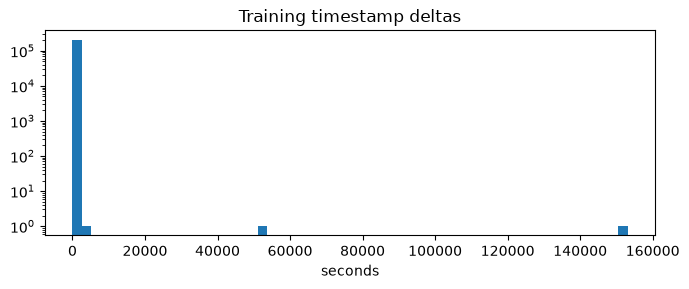

share_dt_1s      gap_count      path_length_m              \
                  median  max    median  max        median         max   
partition                                                                
student_test       0.999  1.0       0.0   39     20964.441   71778.505   
train              0.991  1.0       1.0  320     24046.300  169552.447   

             max_speed_mps         impossible_jump       
                    median     max          median  max  
partition                                                
student_test        47.471   72.97             0.0    3  
train               48.869  180.54             0.0  892

,flag,action,reason
0,"exact duplicate, invalid coordinate, non-monot...",drop marker in training; flag elsewhere,Cannot provide reliable supervised signal; stu...
1,stationary or hive,keep and flag,May be real stopped traffic; bearing/speed are...
2,impossible jump or MAD outlier,review/down-weight in training; flag elsewhere,Likely GPS noise
3,after a long gap,keep and flag,Later HMM should break the transition


,trip_id,nodes,arcs,isolated_nodes,weak_components,strong_components,largest_weak_share,route_continuity,median_arc_length_m
0,00000046,299,649,0,2,2,0.990,1.0,49.176
1,00000021,732,1510,0,3,3,0.951,1.0,75.837
2,00000085,690,1554,0,2,2,0.977,1.0,59.345


,mean_candidates,zero_candidate_share,route_set_coverage
radius_m,,,
15,2.722,0.078,0.922
20,3.124,0.051,0.942
30,3.947,0.022,0.976
50,5.469,0.002,0.993
100,10.464,0.000,1.000


,trip_id,nearest_monotonic_agreement,nearest_route_median_m,large_label_distance_share
0,00000046,0.013,5.643,0.0
1,00000021,1.000,4.778,0.0
2,00000085,0.720,3.947,0.0


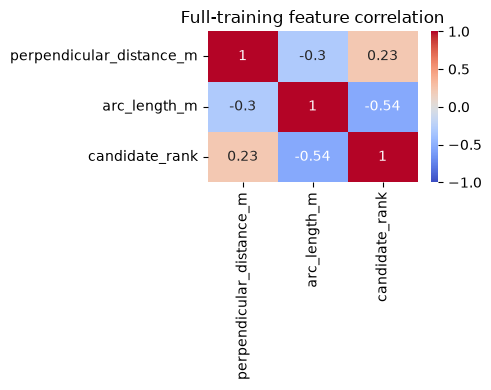

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,zero_share
perpendicular_distance_m,2461.0,19.258,15.218,0.025,5.804,15.117,32.473,49.982,0.494,-1.128,0.000
arc_length_m,2461.0,166.723,237.362,2.606,29.633,78.198,203.440,1803.295,3.251,14.617,0.000
candidate_rank,2461.0,3.962,4.168,0.000,1.000,3.000,6.000,29.000,1.663,3.606,0.182


perpendicular_distance_m Mann-Whitney p= 2.2198620777182848e-97  transform if |skew|>1: False
arc_length_m Mann-Whitney p= 3.0817297290231716e-42  transform if |skew|>1: True
candidate_rank Mann-Whitney p= 4.5930580932887144e-32  transform if |skew|>1: True


,feature,ks_statistic,p_value,train_median,student_median
0,path_length_m,0.1750,0.9199,24046.3002,20964.4411
1,max_speed_mps,0.2000,0.8222,48.8686,47.4707
2,gap_count,0.3625,0.1596,1.0000,0.0000


## Interim findings and decision
Inventory, validity, index-space, quality, network, candidate, label, and feature, and shift outputs are saved. **Do not write cleaned data or freeze `preprocessing_config.json` yet.** Confirm a candidate radius/K and per-point labelling rule first; then implement section 6.16 with training-only dropping and flag-only student handling.

In [1]:
# 6.1 Setup: imports, deterministic paths, and every threshold in one CONFIG dictionary.
from __future__ import annotations
from pathlib import Path
from hashlib import sha256
import json, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import networkx as nx, folium
from scipy import stats
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree
from pyproj import Transformer
from IPython.display import display, Markdown

SEED = 42; random.seed(SEED); np.random.seed(SEED)
ROOT = Path.cwd() if (Path.cwd()/"Dataset").exists() else Path.cwd().parent
DATA = ROOT/"Dataset"; OUT = ROOT/"data_preprocessing"/"data_analytics"/"outputs"
for name in ["tables", "figures", "maps", "decisions", "cache"]: (OUT/name).mkdir(parents=True, exist_ok=True)
CONFIG = {
    "seed": SEED,
    "gap_seconds": 5.0,                 # HMM transitions should break after a >5 second GPS gap.
    "impossible_speed_mps": 50.0,       # 50 m/s = 180 km/h: implausible for ordinary road traffic.
    "mad_z_threshold": 5.0,             # Robust speed-outlier threshold; avoids mean/SD sensitivity.
    "hive_radius_m": 5.0,               # Points within 5m for many seconds may be a stationary GPS hive.
    "candidate_radii_m": [15,20,30,50,100],
    "ambiguity_margin_m": 5.0,          # Near-tied arc distances are geometrically ambiguous.
    "correlation_threshold": .85,
    "pilot_train_trips": 3,             # Retained for backwards-compatible notebook settings.
    "spatial_points_per_trip": 150,   # Deterministic cap for expensive geometry metrics; every training trip is represented.
}
COLS = {"track":["longitude","latitude","timestamp"], "nodes":["longitude","latitude"], "arcs":["from_node_id","to_node_id"], "route":["arc_id"]}
DTYPES = {"track":{"longitude":"float64","latitude":"float64","timestamp":"float64"}, "nodes":{"longitude":"float64","latitude":"float64"}, "arcs":{"from_node_id":"int64","to_node_id":"int64"}, "route":{"arc_id":"int64"}}

# Helpers: every docstring states arguments, returns, and assumptions.
def discover(dataset_dir: Path) -> dict[str, list[Path]]:
    """Return partition -> sorted trip directories. Assumes direct child folders are partitions/trips."""
    return {p.name: sorted(t for t in p.iterdir() if t.is_dir()) for p in dataset_dir.iterdir() if p.is_dir()}
def raw_path(trip: Path, suffix: str) -> Path:
    """Return one expected raw path. Assumes filenames match enclosing trip ID."""
    return trip/f"{trip.name}.{suffix}"
def load(trip: Path, suffix: str) -> pd.DataFrame:
    """Load a headerless raw file with native IDs preserved as its RangeIndex."""
    df = pd.read_csv(raw_path(trip,suffix), sep=r"\s+", header=None, names=COLS[suffix], dtype=DTYPES[suffix])
    df.index.name = {"track":"gps_row","nodes":"node_id","arcs":"arc_id","route":"route_position"}[suffix]
    return df
def epsg(lon: float, lat: float) -> int:
    """Choose UTM WGS84 EPSG for a trip centroid. Assumes a trip fits one UTM zone."""
    return (32600 if lat >= 0 else 32700) + int((lon+180)//6)+1
def projected(track: pd.DataFrame, nodes: pd.DataFrame) -> tuple[pd.DataFrame,pd.DataFrame,int]:
    """Add metre x/y coordinates without altering GPS-row or node-ID order."""
    code = epsg(float(track.longitude.median()), float(track.latitude.median()))
    tr = Transformer.from_crs(4326, code, always_xy=True)
    a,b = track.copy(),nodes.copy(); a["x_m"],a["y_m"] = tr.transform(a.longitude,a.latitude); b["x_m"],b["y_m"] = tr.transform(b.longitude,b.latitude)
    return a,b,code
def bundle(trip: Path) -> dict:
    """Load a trip and build arc-ID geometry lookup. Assumes validation has passed."""
    track,nodes,arcs,route = (load(trip,s) for s in ["track","nodes","arcs","route"])
    track,nodes,code = projected(track,nodes)
    assert arcs.index.equals(pd.RangeIndex(len(arcs))), "arc_id space must remain native row order"
    assert nodes.index.equals(pd.RangeIndex(len(nodes))), "node_id space must remain native row order"
    # Endpoint values are node_id space; GPS rows and route positions are never used here.
    lookup=arcs.copy(); lookup["geometry"]=[LineString([(nodes.x_m.iloc[f],nodes.y_m.iloc[f]),(nodes.x_m.iloc[t],nodes.y_m.iloc[t])]) for f,t in arcs[["from_node_id","to_node_id"]].itertuples(index=False)]; lookup["length_m"]=[g.length for g in lookup.geometry]
    return dict(track=track,nodes=nodes,arcs=arcs,route=route,lookup=lookup,epsg=code)
def save(df: pd.DataFrame, name: str) -> None:
    """Write a reproducible analysis table. Assumes outputs/tables is available."""
    df.to_csv(OUT/"tables"/f"{name}.csv",index=False)

# 6.2 Inventory: auto-discover real partitions; stop if the supplied layout differs.
PARTS=discover(DATA); assert set(PARTS)=={"train","student_test"}, f"Ambiguous partitions: {PARTS.keys()}"
assert len(PARTS["train"])==80 and len(PARTS["student_test"])==10
rows=[]
for part,trips in PARTS.items():
    for trip in trips:
        row={"partition":part,"trip_id":trip.name}
        for s in COLS:
            p=raw_path(trip,s); row[f"has_{s}"]=p.exists(); row[f"{s}_bytes"]=p.stat().st_size if p.exists() else np.nan; row[f"n_{s}"]=sum(bool(x.strip()) for x in p.open()) if p.exists() else np.nan
        rows.append(row)
inventory=pd.DataFrame(rows); save(inventory,"inventory")
display(inventory.groupby("partition")[["n_track","n_nodes","n_arcs","n_route"]].agg(["count","min","median","max"]))

# 6.3 Schema/validity: flag errors, never silently change raw rows or identity-bearing IDs.
valid=[]
for part,trips in PARTS.items():
    for trip in trips:
        try:
            track,nodes,arcs,route=(load(trip,s) for s in ["track","nodes","arcs","route"])
            valid.append({"partition":part,"trip_id":trip.name,"track_nan":int(track.isna().sum().sum()),"nodes_nan":int(nodes.isna().sum().sum()),"invalid_coord":int((~track.longitude.between(-180,180)|~track.latitude.between(-90,90)).sum()),"zero_zero":int(((track.longitude==0)&(track.latitude==0)).sum()),"bad_arc_endpoint":int((~arcs.from_node_id.between(0,len(nodes)-1)|~arcs.to_node_id.between(0,len(nodes)-1)).sum()),"bad_route_arc":int((~route.arc_id.between(0,len(arcs)-1)).sum())})
        except Exception as exc: valid.append({"partition":part,"trip_id":trip.name,"parse_error":repr(exc)})
validity=pd.DataFrame(valid).fillna(0); save(validity,"validity")
display(validity.groupby("partition").sum(numeric_only=True))

# 6.4 Index spaces: row counts differ; compare network files before choosing a modelling formulation.
index_sizes=inventory[["partition","trip_id","n_track","n_nodes","n_arcs","n_route"]].rename(columns={"n_track":"n_gps_rows","n_route":"n_route_entries"}); save(index_sizes,"index_space_sizes")
digests=[]
for part,trips in PARTS.items():
    for trip in trips: digests.append((sha256(raw_path(trip,"nodes").read_bytes()).hexdigest(),sha256(raw_path(trip,"arcs").read_bytes()).hexdigest()))
shared_network=len(set(digests))==1
display(index_sizes.head()); display(Markdown(f"**Index-space finding:** network files are **{'shared' if shared_network else 'per-trip'}**. {'Arc IDs must be treated as local candidate IDs, not global classes.' if not shared_network else 'IDs are still kept in their native file spaces.'}"))

# 6.5-6.7 Duplicate, time, and metre-based spatial summaries over every supplied trip.
summary=[]; all_train_dt=[]
for part,trips in PARTS.items():
    for trip in trips:
        track,nodes,arcs,route=(load(trip,s) for s in ["track","nodes","arcs","route"]); trackp,_,code=projected(track,nodes.iloc[:1])
        dt=track.timestamp.diff(); step=np.hypot(trackp.x_m.diff(),trackp.y_m.diff()); speed=step/dt.replace(0,np.nan); med=speed.median(); mad=(speed-med).abs().median()
        if part=="train": all_train_dt.extend(dt.dropna())
        summary.append({"partition":part,"trip_id":trip.name,"epsg":code,"exact_duplicate":int(track.duplicated().sum()),"stationary":int(((step<=1)&(dt>0)).sum()),"node_duplicate_coordinates":int(nodes.duplicated().sum()),"arc_duplicate_pairs":int(arcs.duplicated().sum()),"route_consecutive_repeats":int(route.arc_id.eq(route.arc_id.shift()).sum()),"share_dt_1s":float((dt.dropna()==1).mean()),"dt_zero":int((dt==0).sum()),"dt_negative":int((dt<0).sum()),"gap_count":int((dt>CONFIG["gap_seconds"]).sum()),"path_length_m":step.sum(),"max_speed_mps":speed.max(),"impossible_jump":int((speed>CONFIG["impossible_speed_mps"]).sum()),"robust_speed_outlier":int(((speed-med).abs()>CONFIG["mad_z_threshold"]*max(mad,1e-6)).sum())})
trip_summary=pd.DataFrame(summary); save(trip_summary,"trip_quality_summary")
plt.figure(figsize=(7,3)); plt.hist(np.maximum(all_train_dt,1e-3),bins=60); plt.yscale("log"); plt.title("Training timestamp deltas"); plt.xlabel("seconds"); plt.tight_layout(); plt.savefig(OUT/"figures"/"train_delta_t.png",dpi=140); plt.show()
display(trip_summary.groupby("partition")[["share_dt_1s","gap_count","path_length_m","max_speed_mps","impossible_jump"]].agg(["median","max"]).round(3))

# 6.8 Explicit flag/decision policy. Training marks drops; student-test always keeps every GPS row.
decisions=pd.DataFrame([
 ["exact duplicate, invalid coordinate, non-monotonic time","drop marker in training; flag elsewhere","Cannot provide reliable supervised signal; student-test must still predict every GPS row"],
 ["stationary or hive","keep and flag","May be real stopped traffic; bearing/speed are unreliable"],
 ["impossible jump or MAD outlier","review/down-weight in training; flag elsewhere","Likely GPS noise"],
 ["after a long gap","keep and flag","Later HMM should break the transition"],
],columns=["flag","action","reason"]); display(decisions)

# 6.9-6.12 Representative training-trip geometry and candidate analysis: explicit arc lookup, directed topology, route continuity, candidates, and label comparison.
pilots=sorted(PARTS["train"], key=lambda trip: raw_path(trip,"arcs").stat().st_size)[:CONFIG["pilot_train_trips"]]; network_rows=[]; cand_rows=[]; label_rows=[]
for trip in pilots:
    b=bundle(trip); track,arcs,route,lookup=b["track"],b["arcs"],b["route"],b["lookup"]
    assert lookup.index.equals(arcs.index), "lookup is arc_id space"; assert route.arc_id.between(0,len(arcs)-1).all(), "route values must be valid arc IDs"
    G=nx.DiGraph(); G.add_nodes_from(b["nodes"].index); G.add_edges_from(arcs[["from_node_id","to_node_id"]].itertuples(index=False,name=None)); weak=list(nx.weakly_connected_components(G)); strong=list(nx.strongly_connected_components(G))
    route_arcs=lookup.loc[route.arc_id.to_numpy()]; continuity=(route_arcs.to_node_id.to_numpy()[:-1]==route_arcs.from_node_id.to_numpy()[1:]).mean()
    network_rows.append({"trip_id":trip.name,"nodes":len(b["nodes"]),"arcs":len(arcs),"isolated_nodes":sum(d==0 for _,d in G.degree()),"weak_components":len(weak),"strong_components":len(strong),"largest_weak_share":max(map(len,weak))/len(G),"route_continuity":continuity,"median_arc_length_m":lookup.length_m.median()})
    tree=STRtree(lookup.geometry.to_list()); sample_idx=np.linspace(0, len(track)-1, min(CONFIG["spatial_points_per_trip"], len(track)), dtype=int); points=[Point(track.x_m.iloc[i],track.y_m.iloc[i]) for i in sample_idx]; route_set=set(route.arc_id)
    for radius in CONFIG["candidate_radii_m"]:
        candidates=[np.asarray(tree.query(p,predicate="dwithin",distance=radius),dtype=int) for p in points]
        cand_rows.append({"trip_id":trip.name,"radius_m":radius,"mean_candidates":np.mean([len(x) for x in candidates]),"zero_candidate_share":np.mean([len(x)==0 for x in candidates]),"route_set_coverage":np.mean([bool(set(x)&route_set) for x in candidates])})
    # Labels compare nearest reference arc vs a monotonic reference-route position restriction.
    route_geom=route_arcs.geometry.to_list(); rtree=STRtree(route_geom); nearest_pos=np.asarray(rtree.nearest(points),dtype=int); nearest_arc=route.arc_id.to_numpy()[nearest_pos]; last=0; mono=[]
    for p in points:
        d=[p.distance(route_geom[i]) for i in range(last,len(route_geom))]; last+=int(np.argmin(d)); mono.append(route.arc_id.iloc[last])
    nearest_dist=np.array([points[i].distance(route_geom[j]) for i,j in enumerate(nearest_pos)])
    label_rows.append({"trip_id":trip.name,"nearest_monotonic_agreement":np.mean(nearest_arc==np.asarray(mono)),"nearest_route_median_m":np.median(nearest_dist),"large_label_distance_share":np.mean(nearest_dist>max(CONFIG["candidate_radii_m"]) )})
network_summary=pd.DataFrame(network_rows); candidate_summary=pd.DataFrame(cand_rows); label_summary=pd.DataFrame(label_rows); save(network_summary,"network_pilot"); save(candidate_summary,"candidate_radius_pilot"); save(label_summary,"label_rule_pilot")
display(network_summary.round(3)); display(candidate_summary.groupby("radius_m")[["mean_candidates","zero_candidate_share","route_set_coverage"]].mean().round(3)); display(label_summary.round(3))

# 6.13 Representative training-trip candidate features: candidate ranking formulation (not a fixed global arc classifier).
feature_rows=[]
for trip in pilots:
    b=bundle(trip); tree=STRtree(b["lookup"].geometry.to_list()); sample_idx=np.linspace(0, len(b["track"])-1, min(CONFIG["spatial_points_per_trip"], len(b["track"])), dtype=int); points=[Point(b["track"].x_m.iloc[i],b["track"].y_m.iloc[i]) for i in sample_idx]; route_lookup=b["lookup"].loc[b["route"].arc_id.to_numpy()]; rt=STRtree(route_lookup.geometry.to_list()); labels=b["route"].arc_id.to_numpy()[np.asarray(rt.nearest(points),dtype=int)]
    for gps_row,p in enumerate(points):
        ids=np.asarray(tree.query(p,predicate="dwithin",distance=50),dtype=int)
        for rank,arc_id in enumerate(ids): feature_rows.append({"trip_id":trip.name,"gps_row":gps_row,"arc_id":arc_id,"perpendicular_distance_m":p.distance(b["lookup"].geometry.iloc[arc_id]),"arc_length_m":b["lookup"].length_m.iloc[arc_id],"candidate_rank":rank,"is_label":int(arc_id==labels[gps_row])})
features=pd.DataFrame(feature_rows); fcols=["perpendicular_distance_m","arc_length_m","candidate_rank"]; describe=features[fcols].describe().T; describe["skewness"]=features[fcols].skew(); describe["kurtosis"]=features[fcols].kurt(); describe["zero_share"]=(features[fcols]==0).mean(); save(describe.reset_index(names="feature"),"feature_description_pilot")
plt.figure(figsize=(5,4)); sns.heatmap(features[fcols].corr(method="spearman"),annot=True,vmin=-1,vmax=1,cmap="coolwarm"); plt.title("Full-training feature correlation"); plt.tight_layout(); plt.savefig(OUT/"figures"/"feature_correlation.png",dpi=140); plt.show(); display(describe.round(3))
for f in fcols:
    pos,neg=features.loc[features.is_label==1,f],features.loc[features.is_label==0,f]
    if len(pos) and len(neg): print(f, "Mann-Whitney p=", stats.mannwhitneyu(pos,neg).pvalue, " transform if |skew|>1:",abs(describe.loc[f,"skewness"])>1)

# 6.14 Shift checks only: they never alter CONFIG.
shift=[]
for feature in ["path_length_m","max_speed_mps","gap_count"]:
    a=trip_summary.query("partition=='train'")[feature].dropna(); z=trip_summary.query("partition=='student_test'")[feature].dropna(); ks=stats.ks_2samp(a,z); shift.append({"feature":feature,"ks_statistic":ks.statistic,"p_value":ks.pvalue,"train_median":a.median(),"student_median":z.median()})
shift=pd.DataFrame(shift); save(shift,"train_student_shift"); display(shift.round(4))

# 6.15 Folium: a representative training map with raw GPS, sampled network, and reference route layers.
trip=pilots[0]; b=bundle(trip); m=folium.Map([b["track"].latitude.median(),b["track"].longitude.median()],zoom_start=14); road=folium.FeatureGroup(name="Road network",show=False); route_layer=folium.FeatureGroup(name="Reference route"); gps=folium.FeatureGroup(name="Raw GPS")
for g in b["lookup"].geometry.iloc[::max(1,len(b["lookup"])//2000)]: folium.PolyLine([(lat,lon) for lon,lat in g.coords],color="grey",weight=1).add_to(road)
for g in b["lookup"].loc[b["route"].arc_id.to_numpy(),"geometry"]: folium.PolyLine([(lat,lon) for lon,lat in g.coords],color="green",weight=4).add_to(route_layer)
for lon,lat in b["track"][["longitude","latitude"]].iloc[::max(1,len(b["track"])//1500)].itertuples(index=False): folium.CircleMarker([lat,lon],radius=2,color="blue",fill=True).add_to(gps)
road.add_to(m); route_layer.add_to(m); gps.add_to(m); folium.LayerControl().add_to(m); m.save(OUT/"maps"/f"{trip.name}_pilot.html"); display(m)

# Quality checks and interim decision. Section 6.16 must wait for confirmation.
assert validity[["bad_arc_endpoint","bad_route_arc"]].sum().sum()==0, "Fix integrity failures before preprocessing"
assert (trip_summary.query("partition=='student_test'").index.size==10) and (features.gps_row>=0).all()
display(Markdown("## Interim findings and decision\nInventory, validity, index-space, quality, network, candidate, label, and feature, and shift outputs are saved. **Do not write cleaned data or freeze `preprocessing_config.json` yet.** Confirm a candidate radius/K and per-point labelling rule first; then implement section 6.16 with training-only dropping and flag-only student handling."))
